In [1]:
%pip install -q qiskit matplotlib pylatexenc

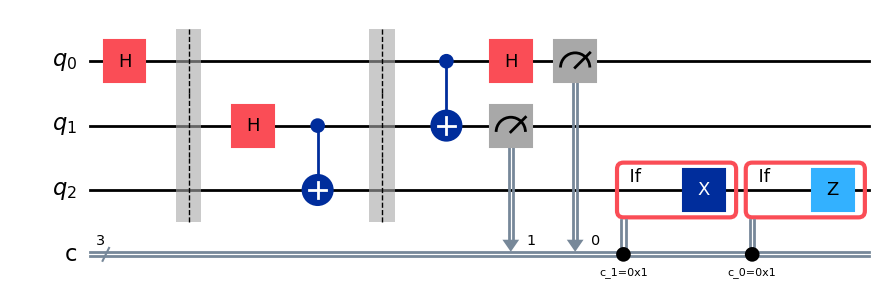

In [5]:
from qiskit import QuantumCircuit

# 1. Tres qubits y tres bits clásicos.
qc = QuantumCircuit(3, 3)

# 2. Estado de prueba que queremos teleportar: |+>.
qc.h(0)

qc.barrier()

# 3. Par entrelazado entre Alice y Bob.
qc.h(1)
qc.cx(1, 2)

qc.barrier()

# 4. Operaciones de Alice.
qc.cx(0, 1)
qc.h(0)

# 5. Mediciones de Alice.
qc.measure(0, 0)
qc.measure(1, 1)

# 6. Correcciones de Bob según los resultados de Alice.
# Si c1 = 1, aplica X sobre q2.
with qc.if_test((qc.clbits[1], 1)):
    qc.x(2)

# Si c0 = 1, aplica Z sobre q2.
with qc.if_test((qc.clbits[0], 1)):
    qc.z(2)

# 7. Dibujamos el circuito.
qc.draw("mpl", fold=-1)

In [6]:
%pip install -q qiskit-aer

In [7]:
from qiskit import transpile
from qiskit_aer import AerSimulator

# Copiamos el circuito para agregar la verificación.
qc_prueba = qc.copy()

qc_prueba.barrier()

# Si Bob recuperó |+>, esta H lo transforma en |0>.
qc_prueba.h(2)

# Medimos q2 y guardamos el resultado en c2.
qc_prueba.measure(2, 2)

# Creamos un simulador ideal, sin ruido.
simulador = AerSimulator()

# Adaptamos el circuito al simulador.
compilado = transpile(
    qc_prueba,
    simulador,
    seed_transpiler=2026
)

# Ejecutamos el circuito completo 1024 veces.
shots = 1024

resultado = simulador.run(
    compilado,
    shots=shots,
    seed_simulator=2026
).result()

conteos = resultado.get_counts()

# Qiskit muestra los bits en el orden c2 c1 c0.
# El primer carácter corresponde a la medición de Bob.
ceros_bob = sum(
    cantidad
    for bits, cantidad in conteos.items()
    if bits[0] == "0"
)

print("Conteos en orden c2 c1 c0:")
print(conteos)

print("\nEjecuciones:", shots)
print("Veces que Bob obtuvo 0 tras la H:", ceros_bob)
print(f"Porcentaje de verificación: {100 * ceros_bob / shots:.2f}%")

Conteos en orden c2 c1 c0:
{'011': 261, '001': 246, '000': 272, '010': 245}

Ejecuciones: 1024
Veces que Bob obtuvo 0 tras la H: 1024
Porcentaje de verificación: 100.00%
